# TP1 — Parte I | EPH 2026-T1
Predicción de informalidad con **15 variables originales** y características construidas.

## 0.1. Librerías
Paquetes para limpieza, descripción, visualización y preparación de los datos.

In [14]:
import pandas as pd
import numpy as np
from pathlib import Path
from os.path import join
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.linalg import qr
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

## 0.2. Rutas
Se respetan las carpetas existentes del repositorio, sin crear otras.

In [ ]:
# Ruta principal
main_path = Path("D:/Github/PE1333_Grupo8/TP_01")

# Carpetas principales
a_path = join(main_path, "A_Inputs")
b_path = join(main_path, "B_Outputs")
c_path = join(main_path, "C_Programs")

# Carpetas secundarias
b_path_data = join(b_path, "B_Data")
b_path_figr = join(b_path, "B_Figure")
b_path_tabl = join(b_path, "B_Table")
b_path_text = join(b_path, "B_Text")

## 0.3. Lectura de datos
Se cargan las bases individual y de hogares; los códigos CNO se leen como texto.

In [16]:
datos_indiv_raw = pd.read_csv(
    join(a_path, "usu_individual_T126.txt"), sep=";", encoding="utf-8",
    low_memory=False, dtype={"PP04D_COD": "string"}
)
datos_hogar_raw = pd.read_csv(
    join(a_path, "usu_hogar_T126.txt"), sep=";", encoding="utf-8", low_memory=False
)
print("Personas:", len(datos_indiv_raw), "| Hogares:", len(datos_hogar_raw))

Personas: 43739 | Hogares: 15447


# 1. Selección y limpieza
Se consideran los ocupados con situación de formalidad identificada en `EMPLEO`.

In [17]:
# Conservar ocupados con clasificación válida
datos_indiv = datos_indiv_raw.loc[
    (datos_indiv_raw["ESTADO"] == 1) &
    (datos_indiv_raw["EMPLEO"].isin([1, 2]))
].copy()

# Variable dependiente: 1 = informal, 0 = formal
datos_indiv["informal"] = (
    datos_indiv["EMPLEO"].map({1: 0, 2: 1}).astype(int)
)

print("Observaciones:", len(datos_indiv))
print(datos_indiv["informal"].value_counts())

Observaciones: 19560
informal
0    10762
1     8798
Name: count, dtype: int64


## 1.2. Selección de variables
Quince variables: demografía (6), educación (1), trabajo (6) y territorio (2). Sin identificadores en X.

In [18]:
# Quince variables originales seleccionadas
variables_demograficas = ["CH03", "CH04", "CH06", "CH07", "CH15", "CH16"]
variables_educacion = ["NIVEL_ED"]
variables_laborales = ["CAT_OCUP", "INTENSI", "PP03C", "PP04A", "PP04C", "P21"]
variables_geograficas = ["REGION", "MAS_500"]
variables_fuente = (variables_demograficas + variables_educacion
                    + variables_laborales + variables_geograficas)
assert len(variables_fuente) == 15 and len(set(variables_fuente)) == 15
assert set(variables_fuente).issubset(datos_indiv.columns)
print("Variables EPH seleccionadas:", len(variables_fuente))
print(variables_fuente)

Variables EPH seleccionadas: 15
['CH03', 'CH04', 'CH06', 'CH07', 'CH15', 'CH16', 'NIVEL_ED', 'CAT_OCUP', 'INTENSI', 'PP03C', 'PP04A', 'PP04C', 'P21', 'REGION', 'MAS_500']


## 1.3. Códigos de no respuesta
Se usan los valores indicados para cada variable en el Diseño de Registro EPH 2026; el 9 no es faltante universal.

In [19]:
print("Variables originales:", len(variables_fuente))
print("Edad de 99 años:", int(datos_indiv["CH06"].eq(99).sum()))
print("Ingreso no declarado (P21=-9):", int(datos_indiv["P21"].eq(-9).sum()))
print("PP04C: no corresponde (0) / no declara (99):",
      int(datos_indiv["PP04C"].eq(0).sum()),
      int(datos_indiv["PP04C"].eq(99).sum()))
print("PP03C: respuesta 0:", int(datos_indiv["PP03C"].eq(0).sum()))
for v in ["NIVEL_ED", "CAT_OCUP", "INTENSI"]:
    print(f"{v}: 9 (Ns/Nr) =", int(datos_indiv[v].eq(9).sum()))


Variables originales: 15
Edad de 99 años: 1
Ingreso no declarado (P21=-9): 3719
PP04C: no corresponde (0) / no declara (99): 1314 2607
PP03C: respuesta 0: 1469
NIVEL_ED: 9 (Ns/Nr) = 0
CAT_OCUP: 9 (Ns/Nr) = 0
INTENSI: 9 (Ns/Nr) = 0


## 1.4. Limpieza y recodificación
Se reemplazan únicamente los códigos Ns/Nr; se distinguen los saltos del cuestionario de la no respuesta.

In [20]:
# Ns/Nr = 9 según el Diseño EPH 2026 (no aplicar a todas las columnas).
for variable in ["CH15", "CH16", "NIVEL_ED", "CAT_OCUP", "INTENSI"]:
    datos_indiv[variable] = datos_indiv[variable].replace(9, np.nan)

# PP03C: 1 = una ocupación; 2 = más de una; 0 = pregunta no aplicada.
datos_indiv["pluriempleo"] = (datos_indiv["PP03C"]
    .map({1: "una", 2: "varias"}).fillna("no_corresponde"))

# PP04C: 99 es Ns/Nr, 0 indica no aplicación; no son tamaños efectivos.
datos_indiv["PP04C"] = datos_indiv["PP04C"].replace(99, np.nan)
datos_indiv["tamano_emp"] = datos_indiv["PP04C"].map(
    lambda x: "no_corresponde" if x == 0 else (
        f"tam_{int(x)}" if pd.notna(x) else "sin_dato")
)

# P21: -9 es ingreso no declarado; 0 se conserva.
datos_indiv["ingreso_no_declara"] = datos_indiv["P21"].eq(-9).astype(int)
datos_indiv["ingreso"] = datos_indiv["P21"].replace(-9, np.nan)
assert (datos_indiv["ingreso"].dropna() >= 0).all()
datos_indiv["log_ingreso"] = np.log1p(datos_indiv["ingreso"])

print("Ns/Nr en tamaño (PP04C):", int((datos_indiv["tamano_emp"] == "sin_dato").sum()))
print("Ingreso no declarado:", int(datos_indiv["ingreso_no_declara"].sum()))
print("Pluriempleo:", datos_indiv["pluriempleo"].value_counts().to_dict())


Ns/Nr en tamaño (PP04C): 2607
Ingreso no declarado: 3719
Pluriempleo: {'una': 16391, 'varias': 1700, 'no_corresponde': 1469}


**Fuente:** INDEC, Diseño de Registro EPH 2026. `PP04C = 99` y `P21 = -9` son no respuestas; `PP03C = 0` y `PP04C = 0` son casos no aplicables en estos datos.

## 1.5. Prevención de filtración
Se excluyen los códigos utilizados directamente para determinar la condición de informalidad.

In [21]:
variables_prohibidas = [
    "EMPLEO", "SECTOR", "PP07H", "PP07I", "PP07G1", "PP07G2",
    "PP07G3", "PP07G4", "PP07G_59", "PP07K", "PP07L",
    "PP05I", "PP05J", "PP05K"
]
assert not set(variables_fuente).intersection(variables_prohibidas)
print("No se incorporan variables que definen EMPLEO.")


No se incorporan variables que definen EMPLEO.


# 2. Variables construidas
Se calculan edad² y características del hogar. El ingreso entra solo como logaritmo e indicador de no declaración.

## 2.1. Construcción
Los identificadores de hogar se utilizan solo para agrupar registros; nunca ingresan en la matriz predictora.

In [22]:
# Edad y edad al cuadrado: no son dos variables originales diferentes.
datos_indiv["edad2"] = datos_indiv["CH06"] ** 2

# Características familiares: se calculan con toda la base individual.
id_hogar = ["CODUSU", "NRO_HOGAR"]
resumen_hogar = (datos_indiv_raw
    .assign(ocupado=lambda d: (d["ESTADO"] == 1).astype(int))
    .groupby(id_hogar, as_index=False)
    .agg(nhogar=("COMPONENTE", "size"), n_ocupados=("ocupado", "sum")))
resumen_hogar["prop_ocupados"] = resumen_hogar["n_ocupados"] / resumen_hogar["nhogar"]
datos_indiv = datos_indiv.merge(
    resumen_hogar[id_hogar + ["nhogar", "prop_ocupados"]],
    on=id_hogar, how="left", validate="many_to_one")
validacion = resumen_hogar.merge(
    datos_hogar_raw[id_hogar + ["IX_TOT"]],
    on=id_hogar, how="left", validate="one_to_one")
print("Diferencias nhogar vs IX_TOT:",
      int((validacion["nhogar"] != validacion["IX_TOT"]).sum()))

# INTENSI reemplaza horas trabajadas en X; no se incorporan ambas.
# P21 se incorpora solo a través del logaritmo y del indicador de no respuesta.
variables_numericas = ["CH06", "edad2", "nhogar", "prop_ocupados",
                       "log_ingreso", "ingreso_no_declara"]
variables_categoricas = ["CH03", "CH04", "CH07", "CH15", "CH16", "NIVEL_ED",
                         "CAT_OCUP", "INTENSI", "PP04A", "REGION", "MAS_500",
                         "pluriempleo", "tamano_emp"]
variables_x = variables_numericas + variables_categoricas
variables_sin_ingreso = [v for v in variables_x
                         if v not in ["log_ingreso", "ingreso_no_declara"]]
assert not set(id_hogar + ["COMPONENTE"]).intersection(variables_x)
print("Predictores antes de dummies:", len(variables_x))

Diferencias nhogar vs IX_TOT: 0
Predictores antes de dummies: 19


C:\Users\JOEL\AppData\Local\Temp\ipykernel_14224\967896855.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .assign(ocupado=lambda d: (d["ESTADO"] == 1).astype(int))


# 3. Faltantes y diferencias de medias
Se identifican valores ausentes y se comparan características de formales e informales mediante pruebas t de Welch.

,N_faltantes,Porcentaje
log_ingreso,3719,19.013
CH15,2,0.010
CH16,1,0.005


Casos con algún valor NaN: 3722


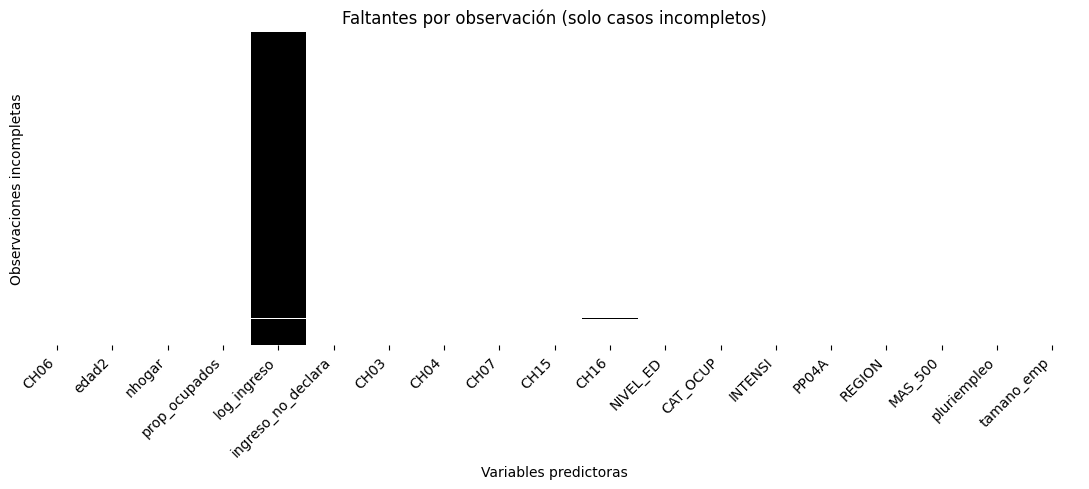

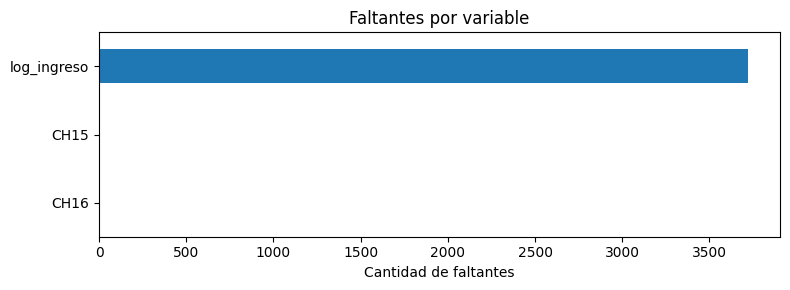

In [23]:
X_original = datos_indiv[variables_x].copy()
y_original = datos_indiv["informal"].copy()
tabla_faltantes = pd.DataFrame({
    "N_faltantes": X_original.isna().sum(),
    "Porcentaje": X_original.isna().mean() * 100
}).sort_values("N_faltantes", ascending=False)
display(tabla_faltantes.loc[tabla_faltantes.N_faltantes > 0].round(3))
print("Casos con algún valor NaN:", int(X_original.isna().any(axis=1).sum()))

# Heatmap enfocado en casos con NaN; útil cuando hay pocos faltantes.
X_faltantes = X_original.loc[X_original.isna().any(axis=1)]
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(X_faltantes.isna(), cmap="Greys", cbar=False, yticklabels=False, ax=ax)
ax.set(title="Faltantes por observación (solo casos incompletos)",
       xlabel="Variables predictoras", ylabel="Observaciones incompletas")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
fig.savefig(join(b_path_figr, "heatmap_faltantes.png"), dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 3))
tabla_faltantes.loc[tabla_faltantes.N_faltantes > 0, "N_faltantes"].sort_values().plot.barh(ax=ax)
ax.set(title="Faltantes por variable", xlabel="Cantidad de faltantes", ylabel="")
fig.tight_layout()
fig.savefig(join(b_path_figr, "faltantes_por_variable.png"), dpi=200, bbox_inches="tight")
plt.show()
tabla_faltantes.to_csv(join(b_path_tabl, "tabla_faltantes.csv"), encoding="utf-8-sig")

In [24]:
# Características categóricas: faltantes explícitos, sin convertirlos en referencia.
datos_modelo = datos_indiv.copy()
X_categorico = datos_modelo[variables_categoricas].fillna("sin_dato").astype(str)
X_dummies = pd.concat([
    datos_modelo[variables_numericas].astype(float),
    pd.get_dummies(X_categorico, drop_first=True, dtype=int)
], axis=1)
y_completo = datos_modelo["informal"].astype(int)

resultados = []
for var in X_dummies.columns:
    formales = X_dummies.loc[y_completo == 0, var].dropna().astype(float)
    informales = X_dummies.loc[y_completo == 1, var].dropna().astype(float)
    t, p = stats.ttest_ind(informales, formales, equal_var=False)
    resultados.append({"Variable": var, "Formal": formales.mean(),
                       "Informal": informales.mean(),
                       "Diferencia": informales.mean() - formales.mean(),
                       "t_stat": t, "p_valor": p})
tabla_medias = pd.DataFrame(resultados)
print("Ocupados:", len(datos_modelo), "| Columnas dummies:", X_dummies.shape[1])
display(tabla_medias.loc[tabla_medias.Variable.isin(
    ["CH06", "edad2", "horastrab", "nhogar", "prop_ocupados", "log_ingreso", "ingreso_no_declara"]
)].round(3))
tabla_medias.to_csv(join(b_path_tabl, "tabla_diferencia_medias_completa.csv"), index=False, encoding="utf-8-sig")

Ocupados: 19560 | Columnas dummies: 65


,Variable,Formal,Informal,Diferencia,t_stat,p_valor
0,CH06,43.483,39.400,-4.083,-21.439,0.000
1,edad2,2034.084,1754.370,-279.714,-16.617,0.000
2,nhogar,3.300,3.878,0.579,22.070,0.000
3,prop_ocupados,0.648,0.627,-0.021,-5.671,0.000
4,log_ingreso,13.787,12.380,-1.407,-38.648,0.000
5,ingreso_no_declara,0.198,0.180,-0.018,-3.117,0.002


## 3.3. Tablas LaTeX
Se exportan una tabla resumida y una completa para el informe.

In [25]:
etiquetas = {
    "CH06": "Edad (años)", "edad2":"Edad al cuadrado",
    "nhogar":"Integrantes del hogar",
    "prop_ocupados":"Proporción de ocupados del hogar",
    "log_ingreso":"Logaritmo del ingreso", "ingreso_no_declara":"Ingreso no declarado",
    "CH15_3":"Lugar de nacimiento (categoría 3)",
    "CH16_2":"Residencia anterior (categoría 2)",
    
    
    "CH04_2":"Mujer", "CAT_OCUP_3":"Asalariado",
    "PP04A_2":"Establecimiento (categoría 2)", "NIVEL_ED_6":"Nivel educativo 6"
}
columnas={"Formal":"Formales","Informal":"Informales", "Diferencia":"Diferencia",
          "t_stat":"t", "p_valor":"p-valor"}
base_medias = tabla_medias.set_index("Variable")[list(columnas)].rename(columns=columnas)
principales=[v for v in etiquetas if v in base_medias.index]
tabla_principal=base_medias.loc[principales].rename(index=etiquetas)

def formato_es(v,dec=3):
    if pd.isna(v): return "--"
    s=f"{v:,.{dec}f}"
    return s.replace(",","#").replace(".",",").replace("#",".")
def formato_latex(t):
    r=t.copy().astype(object)
    for col in t.columns:
        if col=="p-valor":
            r[col]=t[col].map(lambda p: r"$<0{,}001$" if pd.notna(p) and p<.001 else formato_es(p))
        else:r[col]=t[col].map(lambda v: formato_es(v,2 if col=="t" else 3))
    r.index=r.index.map(lambda s: str(s).replace("_",r"\_"))
    return r

for tabla,nombre,etiqueta in [
    (tabla_principal,"tabla_diferencia_medias_resumen.tex","tab:dif_medias_resumen"),
    (base_medias,"tabla_diferencia_medias_completa.tex","tab:dif_medias_completa")]:
    formato_latex(tabla).to_latex(
        join(b_path_tabl, nombre),escape=False,
        caption="Diferencias de medias: trabajadores formales e informales",
        label=etiqueta,column_format="l"+"r"*len(tabla.columns))
print("Resumen:",len(tabla_principal),"filas | Tabla completa:",len(base_medias))
display(formato_latex(tabla_principal))

Resumen: 9 filas | Tabla completa: 65


,Formales,Informales,Diferencia,t,p-valor
Variable,,,,,
Edad (años),"43,483","39,400","-4,083","-21,44","$<0{,}001$"
Edad al cuadrado,"2.034,084","1.754,370","-279,714","-16,62","$<0{,}001$"
Integrantes del hogar,"3,300","3,878","0,579","22,07","$<0{,}001$"
Proporción de ocupados del hogar,"0,648","0,627","-0,021","-5,67","$<0{,}001$"
Logaritmo del ingreso,"13,787","12,380","-1,407","-38,65","$<0{,}001$"
Ingreso no declarado,"0,198","0,180","-0,018","-3,12","0,002"
Mujer,"0,448","0,461","0,013","1,85","0,065"
Asalariado,"0,808","0,596","-0,212","-32,76","$<0{,}001$"
Nivel educativo 6,"0,364","0,090","-0,274","-49,24","$<0{,}001$"


# 4. Entrenamiento y prueba
Se divide 70/30 (semilla 444); las medianas se calculan solo en entrenamiento. Se revisa la dependencia lineal entre dummies.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X_dummies, y_completo, train_size=.70,random_state=444)

# Medianas aprendidas SOLO en entrenamiento para evitar leakage.
imputador = SimpleImputer(strategy="median",keep_empty_features=True)
X_train = pd.DataFrame(imputador.fit_transform(X_train),
                       columns=X_dummies.columns,index=X_train.index)
X_test = pd.DataFrame(imputador.transform(X_test),
                      columns=X_dummies.columns,index=X_test.index)
X_train.insert(0,"const",1.)
X_test.insert(0,"const",1.)
assert not X_train.isna().any().any() and not X_test.isna().any().any()
assert X_train.columns.equals(X_test.columns)

# Diagnóstico de rango: no eliminar variables por su significado económico.
# Se detectan columnas linealmente dependientes con QR (sin quitar la constante).
columnas = X_train.columns.tolist()
matriz = X_train.to_numpy(dtype=float)
_, R, piv = qr(matriz, mode="economic", pivoting=True)
diag = np.abs(np.diag(R))
umbral = max(matriz.shape) * np.finfo(float).eps * diag.max()
rango_inicial = int((diag > umbral).sum())
print("Rango inicial:", rango_inicial, "de", len(columnas))

# Preservar primero la constante y luego columnas en orden; así queda registrado
# exactamente qué dummy se elimina por redundancia.
seleccionadas = ["const"]
eliminadas = []
for col in columnas:
    if col == "const":
        continue
    prueba = X_train[seleccionadas + [col]].to_numpy(dtype=float)
    if np.linalg.matrix_rank(prueba, tol=1e-9) > len(seleccionadas):
        seleccionadas.append(col)
    else:
        eliminadas.append(col)
X_train = X_train[seleccionadas].copy()
X_test = X_test[seleccionadas].copy()
print("Dummies redundantes eliminadas:", eliminadas)
print("Rango final:", np.linalg.matrix_rank(X_train.to_numpy(dtype=float)),
      "de", X_train.shape[1])

assert X_train.columns.is_unique and X_test.columns.is_unique
print("Cantidad de dummies redundantes retiradas:", len(eliminadas))
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Informalidad train/test:", round(y_train.mean(), 4), round(y_test.mean(), 4))

# Conservar un dataset reproducible en el repositorio, con partición explícita.
base_export = pd.concat([X_train,X_test]).sort_index()
base_export["informal"] = pd.concat([y_train,y_test]).sort_index()
base_export["conjunto"] = "train"
base_export.loc[X_test.index,"conjunto"] = "test"
base_export.to_csv(join(b_path_data, "EPH_T126_limpia.csv"),index=False,encoding="utf-8-sig")
print("Base guardada en B_Data:", len(base_export), "observaciones")

Rango inicial: 65 de 66
Dummies redundantes eliminadas: ['CH16_sin_dato']
Rango final: 65 de 65
Cantidad de dummies redundantes retiradas: 1
X_train: (13692, 65) | X_test: (5868, 65)
Informalidad train/test: 0.456 0.4352
Base guardada en B_Data: 19560 observaciones
